In [77]:
import tensorflow as tf
import matplotlib.pyplot as plt
from keras_cv_attention_models import resnet_family

# Loading CIFAR10 Dataset

In [4]:
data = tf.keras.datasets.cifar10.load_data()

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1668s 10us/step


In [ ]:
(x_train, y_train), (x_test, y_test) = data

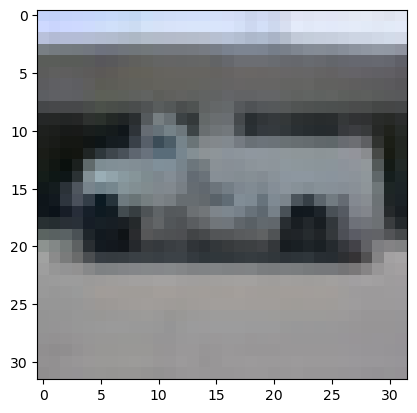

In [83]:
plt.imshow(x_train[110])

# Augmentation

In [58]:
def get_augmentation():
    
    augmentation = tf.keras.Sequential([

        # padding image and then cropping randomly back to 32x32
        tf.keras.layers.ZeroPadding2D(padding=4),
        tf.keras.layers.RandomCrop(32,32),

        tf.keras.layers.RandomFlip("horizontal"),

        tf.keras.layers.RandomBrightness(0.2),

        tf.keras.layers.RandomContrast(0.8)

    ])

    return augmentation

In [ ]:
augmentation = get_augmentation()  

In [67]:
def get_views(image):

    image = tf.expand_dims(image, axis=0)

    view1 = augmentation(image, training=True)
    view2 = augmentation(image, training=True)

    view1 = tf.squeeze(view1, axis=0)
    view2 = tf.squeeze(view2, axis=0)

    return view1, view2

In [68]:
view1, view2 = get_views(x_train[110])

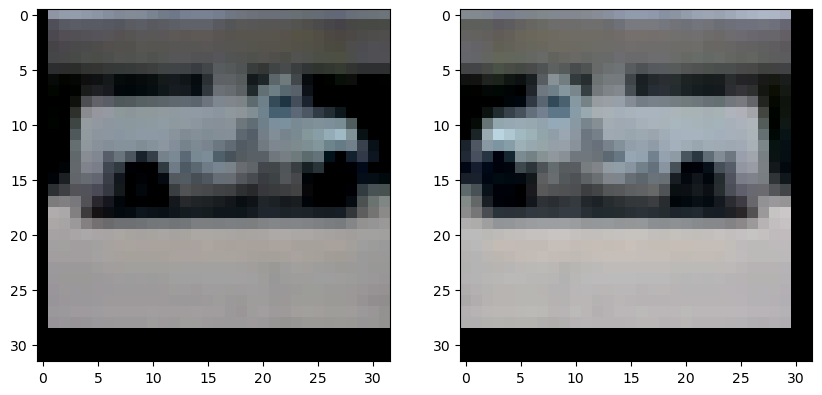

In [85]:
view1 = tf.clip_by_value(view1, 0, 255)
view2 = tf.clip_by_value(view2, 0, 255)

fig, axes = plt.subplots(1,2, figsize=(10,5))


axes[0].imshow(view1.numpy().astype("uint8"))
axes[1].imshow(view2.numpy().astype("uint8"))
plt.show()

In [74]:
train_dataset = tf.data.Dataset.from_tensor_slices(x_train)  # converting x_train into tensorflow Dataset

# each element of dataset would exeprience get_view function
train_dataset = train_dataset.map(
    get_views,
    num_parallel_calls=tf.data.AUTOTUNE   # it specifies how many elements to process in parallel - tf.data.AUTOTUNE means max parallel available
)